# Task 1 — Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** Build an end-to-end supervised classification pipeline on the Iris dataset and benchmark two models.

| Step | What we do |
|---|---|
| 1 | Load the data with Pandas and sanity-check it |
| 2 | Exploratory analysis — Seaborn pairplot, feature correlations |
| 3 | Stratified 80/20 train/test split + `StandardScaler` (fit on train only) |
| 4 | Train `LogisticRegression` and `DecisionTreeClassifier` |
| 5 | Benchmark accuracy, precision, recall, F1 + confusion-matrix heatmaps |
| 6 | Decision-boundary visualisation + cross-validation robustness check |

**Dataset:** 150 samples · 4 numeric features (cm) · 3 balanced classes (*setosa, versicolor, virginica*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Load the dataset

In [2]:
df = pd.read_csv("iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("\nClass balance:\n", df["species"].value_counts())
df.describe()

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64 

Duplicate rows: 1

Class balance:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


The data is clean: no missing values and perfectly balanced classes (50 each). A single duplicate row is a genuine
repeated measurement in the original dataset, so it is kept.

## 2. Exploratory data analysis

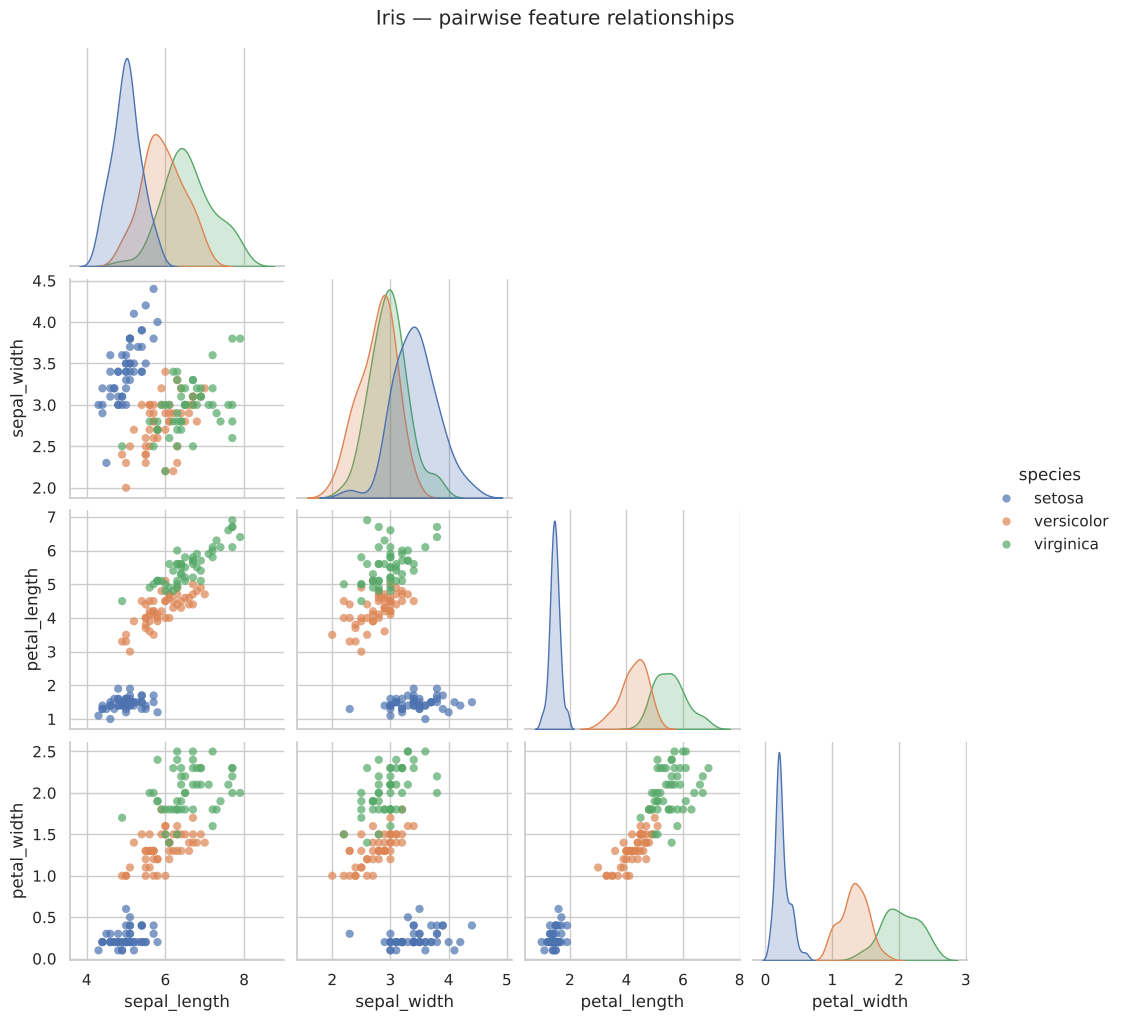

In [4]:
g = sns.pairplot(df, hue="species", corner=True, diag_kind="kde",
                 plot_kws=dict(alpha=0.7, s=35, edgecolor="none"))
g.figure.suptitle("Iris — pairwise feature relationships", y=1.02)
plt.show()

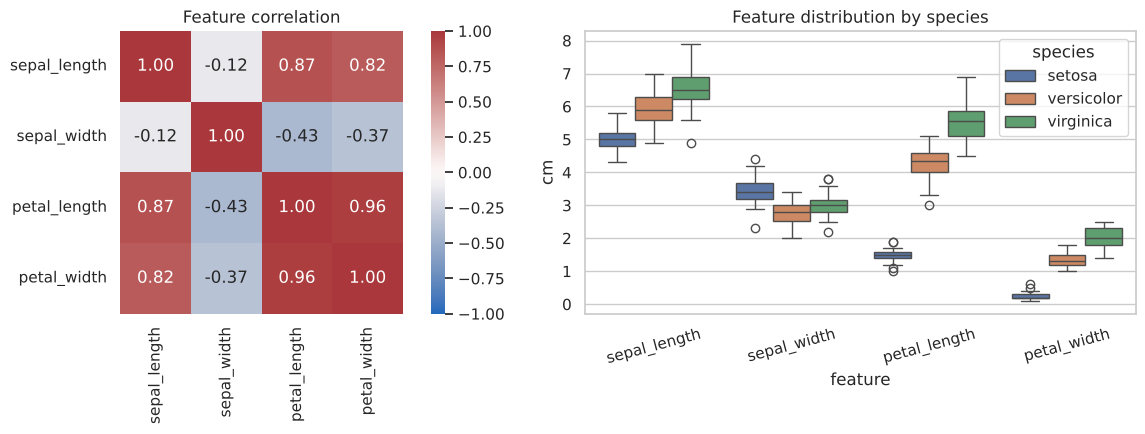

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
corr = df.drop(columns="species").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Feature correlation")

long = df.melt(id_vars="species", var_name="feature", value_name="cm")
sns.boxplot(data=long, x="feature", y="cm", hue="species", ax=axes[1])
axes[1].set_title("Feature distribution by species")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Observations**
- *Setosa* is linearly separable from the other two species on petal length/width alone.
- *Versicolor* and *virginica* overlap slightly — that is where any misclassifications will come from.
- Petal length and petal width are highly correlated (r ≈ 0.96) and are the most discriminative features.

## 3. Train/test split (80/20) and feature scaling

In [6]:
X = df.drop(columns="species")
le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on training data only -> no leakage
X_test_s  = scaler.transform(X_test)

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Test class counts:", dict(zip(class_names, np.bincount(y_test))))
pd.DataFrame(X_train_s, columns=X.columns).describe().loc[["mean", "std"]].round(3)

Train: (120, 4)  Test: (30, 4)
Test class counts: {'setosa': np.int64(10), 'versicolor': np.int64(10), 'virginica': np.int64(10)}


,sepal_length,sepal_width,petal_length,petal_width
mean,-0.000,0.000,0.000,0.000
std,1.004,1.004,1.004,1.004


After scaling, every training feature has mean ≈ 0 and std ≈ 1. The scaler is fitted on the training set only and
then applied to the test set, so no information from the test data leaks into training. Stratification keeps the
10/10/10 class balance in the test set.

## 4. Train the models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)
    print(f"{name:20s} trained  | train acc = {model.score(X_train_s, y_train):.3f}")

Logistic Regression  trained  | train acc = 0.958
Decision Tree        trained  | train acc = 0.992


`max_depth=4` limits the tree so it can't simply memorise the 120 training rows.

## 5. Benchmark — accuracy, precision, recall, F1

In [8]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model")
results.style.format("{:.3f}").highlight_max(axis=0, color="#c7e9c0")

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


In [9]:
for name, y_pred in preds.items():
    print("=" * 60)
    print(f"Classification report — {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Classification report — Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Classification report — Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



### Confusion-matrix heatmaps

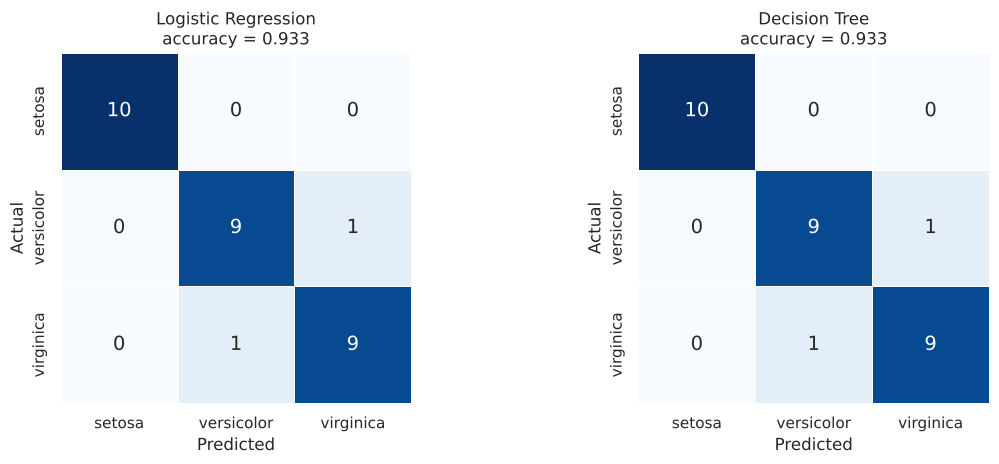

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 14}, linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

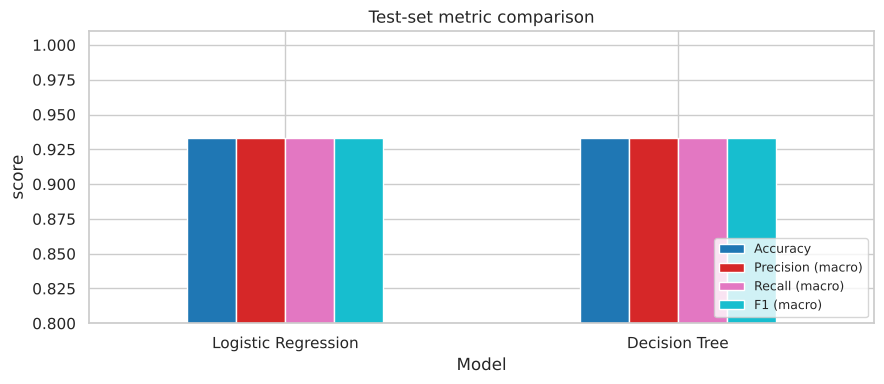

In [11]:
results.plot(kind="bar", figsize=(9, 4), ylim=(0.8, 1.01), rot=0, colormap="tab10")
plt.title("Test-set metric comparison"); plt.ylabel("score")
plt.legend(loc="lower right", fontsize=9); plt.tight_layout(); plt.show()

## 6. Decision-boundary visualisation

Decision boundaries can only be drawn in 2-D, so both models are re-trained on the two most informative features
(**petal length** and **petal width**, scaled). These 2-D models are for visualisation only; the benchmark above uses all four features.

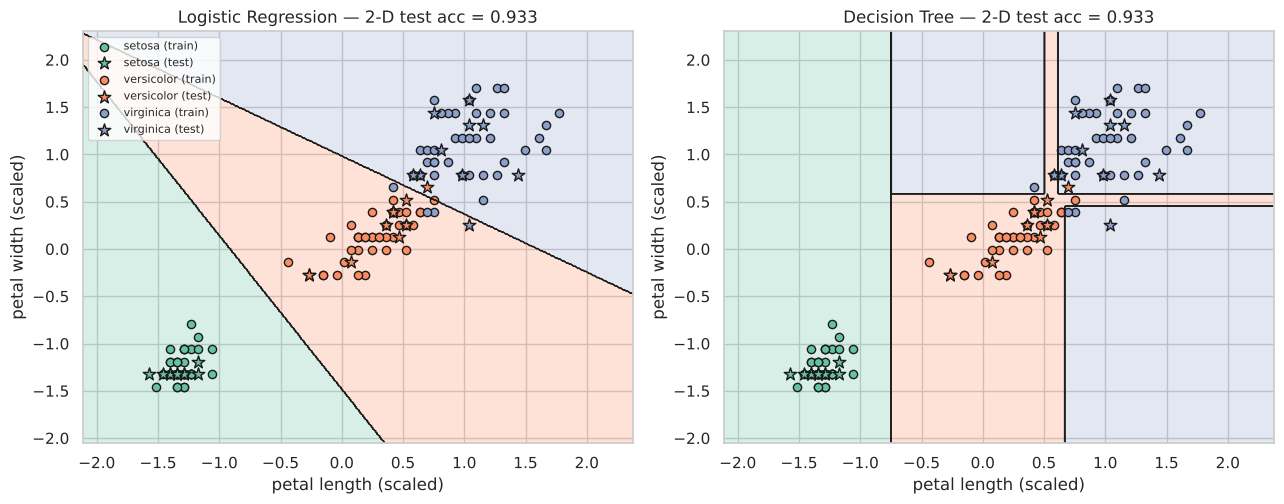

In [12]:
feat2 = ["petal_length", "petal_width"]
sc2 = StandardScaler().fit(X_train[feat2])
Xtr2, Xte2 = sc2.transform(X_train[feat2]), sc2.transform(X_test[feat2])

xx, yy = np.meshgrid(np.linspace(Xtr2[:, 0].min() - 0.6, Xtr2[:, 0].max() + 0.6, 400),
                     np.linspace(Xtr2[:, 1].min() - 0.6, Xtr2[:, 1].max() + 0.6, 400))
palette = sns.color_palette("Set2", 3)
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (name, base) in zip(axes, models.items()):
    m2 = base.__class__(**base.get_params()).fit(Xtr2, y_train)
    Z = m2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=ListedColormap(palette))
    ax.contour(xx, yy, Z, colors="k", linewidths=0.6)
    for k, cls in enumerate(class_names):
        ax.scatter(*Xtr2[y_train == k].T, color=palette[k], edgecolor="k", s=35, label=f"{cls} (train)")
        ax.scatter(*Xte2[y_test == k].T, color=palette[k], edgecolor="k", s=90, marker="*", label=f"{cls} (test)")
    ax.set_title(f"{name} — 2-D test acc = {m2.score(Xte2, y_test):.3f}")
    ax.set_xlabel("petal length (scaled)"); ax.set_ylabel("petal width (scaled)")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Logistic Regression draws straight (linear) boundaries between classes; the Decision Tree carves the space into
axis-aligned rectangles. Both isolate *setosa* cleanly — the only contested region is the versicolor/virginica border.

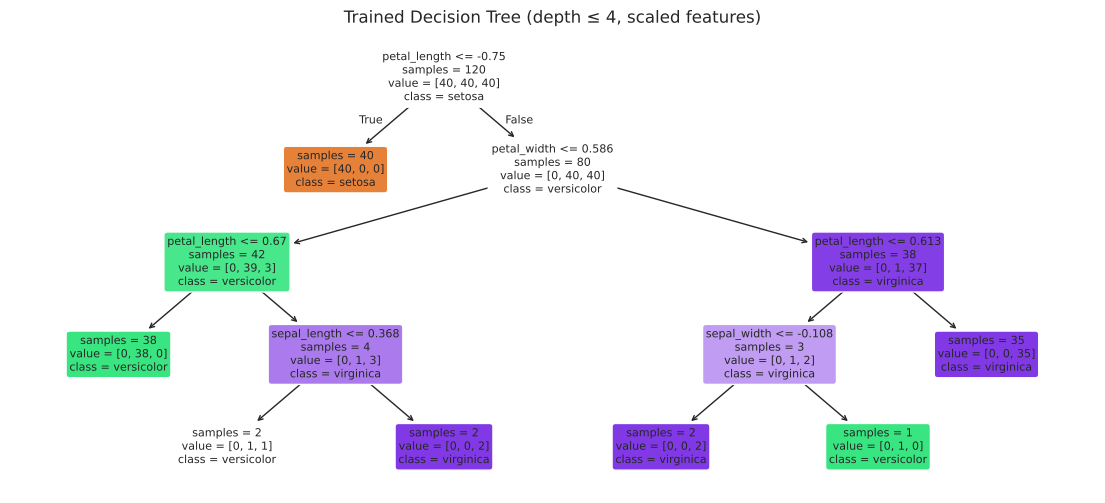

Decision-tree feature importance:
 sepal_length    0.006
sepal_width     0.017
petal_width     0.411
petal_length    0.566
dtype: float64 

Logistic-regression coefficients (per class):


,sepal_length,sepal_width,petal_length,petal_width
setosa,-1.09,1.02,-1.8,-1.69
versicolor,0.54,-0.36,-0.2,-0.81
virginica,0.55,-0.66,2.0,2.49


In [13]:
plt.figure(figsize=(14, 6))
plot_tree(models["Decision Tree"], feature_names=X.columns, class_names=class_names,
          filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Trained Decision Tree (depth ≤ 4, scaled features)"); plt.show()

imp = pd.Series(models["Decision Tree"].feature_importances_, index=X.columns).sort_values()
coef = pd.DataFrame(models["Logistic Regression"].coef_, index=class_names, columns=X.columns)
print("Decision-tree feature importance:\n", imp.round(3), "\n")
print("Logistic-regression coefficients (per class):"); coef.round(2)

## 7. Robustness check — 5-fold stratified cross-validation

With only 30 test samples, a single misclassification moves accuracy by 3.3 points. Cross-validation on the full
dataset gives a more reliable estimate. The scaler sits inside a `Pipeline` so it is re-fitted on each training fold.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", model)])
    for metric in ["accuracy", "f1_macro"]:
        s = cross_val_score(pipe, X, y, cv=cv, scoring=metric)
        cv_rows.append({"Model": name, "Metric": metric, "Mean": s.mean(), "Std": s.std()})
cv_df = pd.DataFrame(cv_rows).pivot(index="Model", columns="Metric", values=["Mean", "Std"])
cv_df.round(3)

Mean               Std         
Metric              accuracy f1_macro accuracy f1_macro
Model                                                  
Decision Tree          0.953    0.953    0.034    0.034
Logistic Regression    0.953    0.953    0.045    0.045

## 8. Conclusions

- Both models classify Iris with high accuracy; *setosa* is always perfectly separated.
- All errors occur between *versicolor* and *virginica*, which overlap in feature space (seen in the pairplot).
- The two models **tie**: 93.3% accuracy and 0.933 macro-F1 on the held-out test set (2 errors out of 30 each), and
  95.3% mean accuracy in 5-fold cross-validation. On a dataset this small and clean, the choice of model matters less
  than the inherent versicolor/virginica overlap.
- The **Decision Tree** fits the training data more tightly (99.2% vs 95.8% train accuracy) without gaining on test data —
  a mild sign of over-fitting, even with `max_depth=4`. It is highly interpretable and relies almost entirely on petal
  measurements (≈98% of importance).
- **Logistic Regression** gives smooth, linear boundaries and calibrated class probabilities; it would be the default
  pick for a production pipeline, though its CV spread here (±0.045) is slightly wider than the tree's (±0.034).
- Feature scaling matters for Logistic Regression (regularisation and optimisation are scale-sensitive); tree models are
  scale-invariant, so scaling is applied for a uniform pipeline rather than to improve the tree.

**Possible extensions:** hyper-parameter tuning with `GridSearchCV`, adding SVM / k-NN / Random Forest, and repeating the
pipeline on the Wine dataset (`sklearn.datasets.load_wine`).